# Resume Analyzer Using Natural Language Processing
**NLP practicals 1-10 + five mandatory preprocessing experiments + transformer fine-tuning**

Team: *Member 1, Member 2, Member 3, Member 4* (edit) · Department / College / Year: *(edit)*

**How to run**
* **Google Colab:** upload `resume-analyzer-nlp.zip` (Files panel), then run all cells. Set `Runtime → Change runtime type → GPU` to retrain the transformer quickly.
* **Local:** `pip install -r requirements.txt && python -m spacy download en_core_web_sm`, then open this notebook from the `notebooks/` folder.

Every cell calls the same tested code that lives in `src/` (one implementation, no copy-paste duplicates).

In [1]:
import os, sys, json, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not Path("resume-analyzer-nlp").exists() and Path("resume-analyzer-nlp.zip").exists():
    subprocess.run(["unzip", "-q", "resume-analyzer-nlp.zip"], check=True)
ROOT = Path("resume-analyzer-nlp") if Path("resume-analyzer-nlp/src").exists() else \
       (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
os.chdir(ROOT); sys.path.insert(0, str(Path.cwd()))
if IN_COLAB:
    subprocess.run("pip -q install pdfplumber pymupdf contractions langdetect gensim streamlit python-docx", shell=True)
    subprocess.run("python -m spacy download en_core_web_sm -q", shell=True)
import nltk
for p in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger",
          "averaged_perceptron_tagger_eng", "treebank", "universal_tagset"]:
    nltk.download(p, quiet=True)
import pandas as pd
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
from IPython.display import Image, display, SVG
print("Project root:", Path.cwd())

Project root: /home/claude/resume-analyzer-nlp


[nltk_data] Error loading punkt: Security Violation [pathsec.urlopen]:
[nltk_data]     refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading punkt_tab: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

## Stages A-E: dataset inventory, pilot sample, preprocessing, full dataset, target check
Folder names in the supplied zip are mapped to canonical labels (`Health care`→Healthcare, `Hr`→HR, trailing spaces removed).
The content check (lexicon evidence per domain) flags resumes whose text disagrees with their folder label — it never relabels silently.

In [2]:
from src import build_dataset
build_dataset.main()

Stage A: inventory ...


category
Agriculture    20
Engineering    20
Finance        20
HR             20
Healthcare     20
Stage B: pilot selection ...
Stage C: preprocess pilot ...


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Stage D: process all available resumes ...


Stage E: target check ...
             available_valid  target  shortfall  pilot  flagged_for_review
category                                                                  
Engineering               20      20          0      5                   0
HR                        20      20          0      5                   0
Finance                   20      20          0      5                   0
Healthcare                20      20          0      5                   0
Agriculture               20      20          0      5                   0
{
  "files_found": 100,
  "valid_resumes": 100,
  "pilot_size": 25,
  "full_dataset_size": 100,
  "target_total": 100,
  "target_met": true,
  "pilot_equals_full_dataset": false,
  "exact_duplicates": 0,
  "near_duplicates": 0,
  "max_pairwise_similarity": 0.7901
}
Flagged for manual review:


In [3]:
manifest = pd.read_csv("data/dataset_manifest.csv")
display(manifest[["resume_id","source_filename","category","n_pages","extraction_method","extraction_status","n_words","title_line"]])
display(pd.read_csv("results/category_counts.csv"))
ds = pd.read_csv("data/resume_dataset.csv")
display(ds[["resume_id","category","content_domain","label_check","review_required","skill_count","job_titles"]])

,resume_id,source_filename,category,n_pages,extraction_method,extraction_status,n_words,title_line
0,AGR_01,11197262.pdf,Agriculture,2,pdfplumber,ok,703,PLANT PROTECTION AND QUARANTINE TECHNICIAN
1,AGR_02,SYN_AGR_01.pdf,Agriculture,1,pdfplumber,ok,278,Aarav Iyer
2,AGR_03,SYN_AGR_02.pdf,Agriculture,1,pdfplumber,ok,312,Rhea Banerjee
3,AGR_04,SYN_AGR_03.pdf,Agriculture,1,pdfplumber,ok,289,Amara Iyer
4,AGR_05,SYN_AGR_04.pdf,Agriculture,1,pdfplumber,ok,309,Maria Khan
...,...,...,...,...,...,...,...,...
95,HLT_16,SYN_HLT_13.pdf,Healthcare,1,pdfplumber,ok,278,Kavya Sandhu
96,HLT_17,SYN_HLT_14.pdf,Healthcare,1,pdfplumber,ok,284,Gauri Rossi
97,HLT_18,SYN_HLT_15.pdf,Healthcare,1,pdfplumber,ok,301,Uday Saxena
98,HLT_19,SYN_HLT_16.pdf,Healthcare,1,pdfplumber,ok,290,Leah Qureshi


,category,available_valid,target,shortfall,pilot,flagged_for_review
0,Engineering,20,20,0,5,0
1,HR,20,20,0,5,0
2,Finance,20,20,0,5,0
3,Healthcare,20,20,0,5,0
4,Agriculture,20,20,0,5,0


,resume_id,category,content_domain,label_check,review_required,skill_count,job_titles
0,AGR_01,Agriculture,Agriculture,consistent,False,15,Plant Protection and Quarantine Technician; Flammulated Owl Research Lab Technician; Wildlife Biology Field Assistant
1,AGR_02,Agriculture,Agriculture,consistent,False,24,[name]
2,AGR_03,Agriculture,Agriculture,consistent,False,19,[name]
3,AGR_04,Agriculture,Agriculture,consistent,False,17,[name]
4,AGR_05,Agriculture,Agriculture,consistent,False,18,[name]
...,...,...,...,...,...,...,...
95,HLT_16,Healthcare,Healthcare,consistent,False,16,Kavya Sandhu
96,HLT_17,Healthcare,Healthcare,consistent,False,15,[name]
97,HLT_18,Healthcare,Healthcare,consistent,False,19,[name]
98,HLT_19,Healthcare,Healthcare,consistent,False,12,Leah Qureshi


## Practical 1 — NLP applications and tools
NLTK, spaCy and Hugging Face Transformers are executed below on a real resume sentence. AllenNLP is checked (archived project, incompatible with current PyTorch/Python).
Cloud platforms (Google Cloud Natural Language, AWS Comprehend, Azure AI Language) are compared in a table only — no paid API keys are needed for this project.

In [4]:
from src import nlp_tools_demo
nlp_tools_demo.main()
display(pd.DataFrame(nlp_tools_demo.CLOUD_PLATFORMS))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 3551.81it/s]


[transformers] RobertaModel LOAD REPORT from: /home/claude/resume-analyzer-nlp/models/pretrained/roberta-base-spacy
Key                 | Status  | 
--------------------+---------+-
pooler.dense.bias   | MISSING | 
pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{
 "sentence": "Experience with advanced material selection for rapid prototyping, advanced manufacturing, welding and 3D printing.",
 "nltk": {
  "version": "3.10.3",
  "tokens": [
   "Experience",
   "with",
   "advanced",
   "material",
   "selection",
   "for",
   "rapid",
   "prototyping",
   ",",
   "advanced",
   "manufacturing",
   ",",
   "welding",
   "and",
   "3D",
   "printing",
   "."
  ],
  "pos": [
   [
    "Experience",
    "NN"
   ],
   [
    "with",
    "IN"
   ],
   [
    "advanced",
    "JJ"
   ],
   [
    "material",
    "NN"
   ],
   [
    "selection",
    "NN"
   ],
   [
    "for",
    "IN"
   ],
   [
    "rapid",
    "JJ"
   ],
   [
    "prototyping",
    "NN"
   ],
   [
    ",",
    ","
   ],
   [
    "advanced",
    "VBD"
   ],
   [
    "manufacturing",
    "NN"
   ],
   [
    ",",
    ","
   ],
   [
    "welding",
    "NN"
   ],
   [
    "and",
    "CC"
   ],
   [
    "3D",
    "CD"
   ],
   [
    "printing",
    "NN"
   ],
   [
    ".",
    "."
   ]
  ]
 },

,platform,features,custom_models,access
0,Google Cloud Natural Language API,"entities, sentiment, syntax, content classification",AutoML / Vertex AI,"REST/gRPC, API key or service account (billed)"
1,AWS Comprehend,"entities, key phrases, sentiment, PII detection, language detection",custom classifier & custom entity recognizer,"boto3 SDK, IAM credentials (billed)"
2,Azure AI Language (Text Analytics),"NER, PII redaction, key phrases, sentiment, language",custom text classification / custom NER,"REST/SDK, endpoint + key (billed)"


## Practical 2 — Application, problem statement and I/O specification
**Problem.** Recruiters receive resumes in inconsistent PDF layouts. We build an NLP system that (A) classifies a resume into one of five domains — Engineering, HR, Finance, Healthcare, Agriculture — and (B) extracts skills, education, job titles, organizations and experience information.

| | Task A — classification | Task B — information extraction |
|---|---|---|
| Input | resume PDF / text | resume text |
| Output | one of 5 domains + class probabilities | skills (with domain), degrees, institutions, job titles, organizations, date ranges |
| Method | TF-IDF + LogReg baseline; fine-tuned transformer | dictionary PhraseMatcher, regex, spaCy NER, EntityRuler |

Related NLP applications (syllabus): machine translation, text categorization (**our Task A**), summarization, chatbots, plagiarism detection (≈ our near-duplicate check), spelling/grammar checking, sentiment analysis, question answering, personal assistants, tutoring systems.

In [5]:
r = ds.set_index("resume_id").loc["ENG_05"]
print("INPUT (first 500 chars of extracted text):\n", r["extracted_text"][:500])
print("\nOUTPUT  label:", r["category"], "| skills:", r["extracted_skills"][:200])
print("education:", r["education"]); print("job titles:", r["job_titles"])

INPUT (first 500 chars of extracted text):
 MECHANICAL ENGINEERING INTERN
Summary
CAD | CAM | Finite Element Analysis | Mechanical Design | Product Design and Development
Skills
5 years of experience with CAD packages (SolidWorks, Autodesk Inventor, AutoCAD, CATIA, PTC CREO)
2.5 years of experience with CAE Softwares (HyperMesh, Abaqus, ANSYS, Optistruct)
2.5 years of experience with Analysis (Linear & Non-linear Static, Dynamic, GD & T, Tolerance Analysis, Design Optimization)
Experience with Sheet metal, Design for manufacturing, genera

OUTPUT  label: Engineering | skills: manufacturing; cad; cam; finite element analysis; autocad; welding; solidworks; autodesk inventor; catia; ansys; bill of materials; prototyping; aerospace; mechanical design; product design; ptc creo;
education: {"degrees": ["Bachelor of Technology"], "institutions": ["Aerospace Engineering Illinois Institute of Technology", "Mechanical Engineering Narsee Monjee Institute of Management Studies"], "qualifications":

## Five mandatory preprocessing experiments (Practicals 3 & 4)
Each experiment is independent; change `RESUME` to run it on another resume.

In [6]:
from src import preprocessing_experiments as pe
RESUME = "HR_01"
raw = ds.set_index("resume_id").loc[RESUME, "extracted_text"]

### Experiment 1 — Text cleaning and normalization (HTML tags, special characters, whitespace, lowercasing, number words → digits, optional number removal)

In [7]:
res1 = pe.EXPERIMENTS[1](raw)
pd.DataFrame(res1['stats'])


--- Exp1 HTML: BEFORE ---
<html><body><h2>HR PERSONNEL ASSISTANT</h2><p>Summary</p><p>I am a U.S. citizen who is authorized to work in the US for any employer. I have worked 8 years as an Office Clerk, 2 years as a Student</p><p>Intern/Office Assistant, and 4 years as a Contractor. I am applying for the Data Entry Clerk posi
--- Exp1 HTML: AFTER ---
   HR PERSONNEL ASSISTANT
 Summary
 I am a U.S. citizen who is authorized to work in the US for any employer. I have worked 8 years as an Office Clerk, 2 years as a Student
 Intern/Office Assistant, and 4 years as a Contractor. I am applying for the Data Entry Clerk position (Advert ID# 224278 Adver

--- Exp1 full cleaning: BEFORE ---
HR PERSONNEL ASSISTANT
Summary
I am a U.S. citizen who is authorized to work in the US for any employer. I have worked 8 years as an Office Clerk, 2 years as a Student
Intern/Office Assistant, and 4 years as a Contractor. I am applying for the Data Entry Clerk position (Advert ID# 224278 Advert ID# 224278).
M

,step,chars,whitespace_tokens
0,0_raw,5329,720
1,1_html_removed,480,75
2,2_noise_handled,5211,694
3,3_special_chars,5211,694
4,4_whitespace,5199,694
5,5_lowercase,5199,694
6,6_numwords_to_digits,5199,694
7,7_numbers_removed(optional),5136,683
8,7b_numbers_removed_keep_years,5178,689


### Experiment 2 — Sentence splitting and contraction handling

In [8]:
res2 = pe.EXPERIMENTS[2](raw)


Exp2 sentence counts: naive (newlines ignored)=44, resume-aware NLTK=77, spaCy=77
  • HR PERSONNEL ASSISTANT
  • Summary
  • I am a U.S. citizen who is authorized to work in the US for any employer.
  • I have worked 8 years as an Office Clerk, 2 years as a Student
  • Intern/Office Assistant, and 4 years as a Contractor.
  • I am applying for the Data Entry Clerk position (Advert ID# 224278 Advert ID# 224278).
  • My skills and experiences include: Administrative Support, Auditing, File Management, Meeting Facilitation, Office Materials Management, &
  • Inventory Management.
Contractions: {
 "real_resume_lines_with_apostrophes": [
  {
   "before": "Bachelor's of Arts : Political Science and Law 2007 Montclair State University , , US Bachelor's of Arts Degree in Political Science",
   "after": "Bachelor's of Arts : Political Science and Law 2007 Montclair State University , , US Bachelor's of Arts Degree in Political Science"
  }
 ],
 "demo_sentence": {
  "before": "I'm a detail-orie

### Experiment 3 — Tokenization and skill/phrase extraction (multi-word skills kept together)

In [9]:
res3 = pe.EXPERIMENTS[3](raw)


Exp3 token counts: {'whitespace': 694, 'regex': 698, 'nltk': 860, 'spacy': 876} skill-aware: 839
Multi-word skills kept as one token: ['administrative_support', 'customer_service', 'data_entry', 'file_management', 'human_resources', 'inventory_management', 'microsoft_word', 'ms_excel']
Demo: {"nltk_word_tokenize": ["skilled", "in", "human", "resource", "management", ",", "data", "entry", ",", "machine", "learning", "and", "financial", "analysis", "(", "c++", ",", "r", "&", "d", ")", "."], "skill_aware": ["skilled", "in", "human_resource_management", ",", "data_entry", ",", "machine_learning", "and", "financial_analysis", "(", "c++", ",", "r", "&", "d", ")", "."]}
Dictionary skills: ['personnel', 'data entry', 'administrative support', 'auditing', 'outlook', 'powerpoint', 'peoplesoft', 'documentation', 'scheduling', 'file management', 'inventory management', 'microsoft word', 'ms excel', 'customer service', 'human resources', 'audit', 'sales', 'word']
Top noun phrases: [('administrativ

### Experiment 4 — Stopword removal, stemming and lemmatization

In [10]:
res4 = pe.EXPERIMENTS[4](raw)
pd.DataFrame(res4['table_head'])


Exp4: {'tokens': 631, 'after_stopwords': 496, 'stopword_reduction_pct': 21.4, 'vocabulary_size': {'original': 282, 'porter': 237, 'lancaster': 230, 'wordnet_lemma': 253}}
         token      porter    snowball   lancaster wordnet_lemma spacy_lemma
0           hr          hr          hr          hr            hr          hr
1    personnel   personnel   personnel   personnel     personnel   personnel
2    assistant      assist      assist      assist     assistant   assistant
3      summary     summari     summari         sum       summary     summary
4      citizen     citizen     citizen         cit       citizen     citizen
5   authorized      author      author        auth     authorize   authorize
6         work        work        work        work          work        work
7           us          us          us          us             u          us
8     employer      employ      employ      employ      employer    employer
9       worked        work        work        work        

,token,porter,snowball,lancaster,wordnet_lemma,spacy_lemma
0,hr,hr,hr,hr,hr,hr
1,personnel,personnel,personnel,personnel,personnel,personnel
2,assistant,assist,assist,assist,assistant,assistant
3,summary,summari,summari,sum,summary,summary
4,citizen,citizen,citizen,cit,citizen,citizen
5,authorized,author,author,auth,authorize,authorize
6,work,work,work,work,work,work
7,us,us,us,us,u,us
8,employer,employ,employ,employ,employer,employer
9,worked,work,work,work,worked,work


### Experiment 5 — Noise handling, personal-information anonymization and script/language validation

In [11]:
res5 = pe.EXPERIMENTS[5](raw)


Exp5 noise: ['Company Name City , State HR Personnel Assistant 03/2013 to 04/2014', 'Company Name City , State Assistant Store Clerk 05/2011 to 01/2012', 'Company Name City , State Office Clerk/ Federal Contractor 06/2008 to 10/2009'] -> ['  HR Personnel Assistant 03/2013 to 04/2014', '  Assistant Store Clerk 05/2011 to 01/2012', '  Office Clerk/ Federal Contractor 06/2008 to 10/2009']
Anonymization demo (synthetic contact header + real resume text):
 [NAME]
[EMAIL] | [PHONE] | [ADDRESS], Springfield [ADDRESS]
[URL]
HR PERSONNEL ASSISTANT
Summary
I am a U.S. citizen who is authorized to work in the US for any employer. I have worked 8 years as an Office Clerk, 2 years as a Student
Intern/Office Assistant, and 4 years as a Contractor. I am applying for the Data Entry Clerk position (Advert ID# 224278 Advert ID# 
Script validation (real): {'latin_ratio': 1.0, 'scripts': {'LATIN': 4215}, 'language': 'en', 'language_prob': 1.0, 'valid_english_latin': True, 'non_english_lines': {}, 'mixed_

### Preprocessing effect over all resumes + task-specific configurations

,resume_id,category,raw_chars,cleaned_chars,raw_whitespace_tokens,nltk_tokens,alnum_tokens_no_stopwords,"classification_tokens(lemma,skill-aware)",unique_raw_tokens,unique_classification_tokens,multiword_skill_tokens,skills_extracted
0,AGR_01,Agriculture,5023,4825,703,732,516,490,410,341,9,15
1,AGR_02,Agriculture,2022,1875,278,296,188,174,206,150,10,24
2,AGR_03,Agriculture,2189,2041,312,322,213,194,214,156,10,19
3,AGR_04,Agriculture,1961,1787,289,271,187,170,189,132,10,17
4,AGR_05,Agriculture,2159,2008,309,301,193,185,207,152,8,18
...,...,...,...,...,...,...,...,...,...,...,...,...
95,HLT_16,Healthcare,2032,1912,278,297,188,174,197,143,13,16
96,HLT_17,Healthcare,2013,1835,284,263,185,173,200,148,11,15
97,HLT_18,Healthcare,2152,2008,301,305,191,182,208,151,10,19
98,HLT_19,Healthcare,2084,1938,290,291,188,184,194,149,6,12


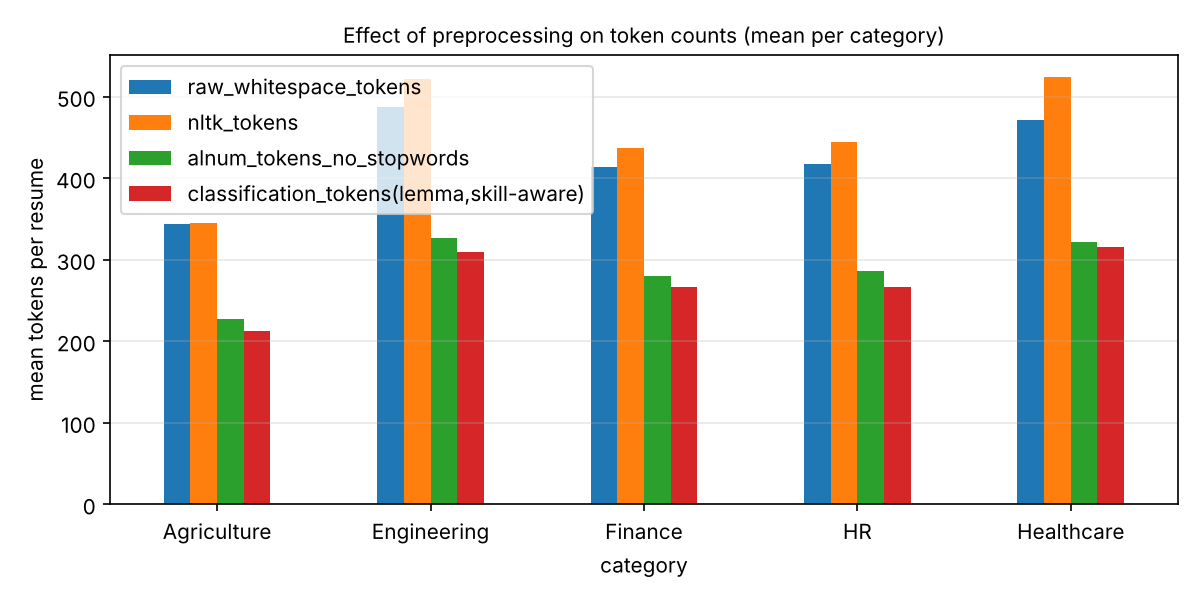

--- config=classification:
 finance manager executive profile financial lead company oversight commit strategic management quality performance partner organization leader effectively align support key initiative build retains high performance team hire develop motivate skilled professional skill highlight business_development  

--- config=stemmed:
 financ manag execut profil financi lead compani oversight commit strateg manag qualiti perform partner organ leader effect align support key initi build retain high perform team hire develop motiv skill profession skill highlight business_development highli analyt performance_management budgeting_an 

--- config=transformer:
 FINANCE MANAGER Executive Profile Financial Lead with company oversight, committed to strategic management and quality performance. Partner with organization leaders to effectively align with and support key initiatives. Builds and retains high performance teams by hiring, developing and motivating  



In [12]:
cmp = pe.preprocessing_comparison(ds); pe.plot_comparison(cmp)
display(cmp); display(Image("results/plots/preprocessing_token_counts.png"))
from src.preprocessing import preprocess
sample = ds.set_index("resume_id").loc["FIN_02", "anonymized_text"][:700]
for cfg in ["classification", "stemmed", "transformer"]:
    print(f"--- config={cfg}:\n", preprocess(sample, cfg)["text"][:300], "\n")

## Practical 5 — Shallow parsing, chunking, POS tagging, dependency parsing, CFG parse trees


=== [AGR_01] Environmental Biologist and experienced researcher with expertise in data collection and study.
POS (NLTK): Environmental/JJ Biologist/NNP and/CC experienced/VBD researcher/NN with/IN expertise/NN in/IN data/NNS collection/NN and/CC study/NN ./.
Chunks: [NP Environmental Biologist]; [VP experienced researcher with expertise in data collection]; [NP researcher]; [PP with expertise]; [NP expertise]; [PP in data collection]; [NP data collection]; [NP study]
Chunk tree: (S (NP Environmental/JJ Biologist/NNP) and/CC (VP experienced/VBD (NP researcher/NN) (PP with/IN (NP expertise/NN)) (PP in/IN (NP data/NNS collection/NN))) and/CC (NP study/NN) ./.)
Dependencies: Environmental<-amod-Biologist, Biologist<-ROOT-Biologist, and<-cc-Biologist, experienced<-conj-Biologist, researcher<-dobj-experienced, with<-prep-experienced, expertise<-pobj-with, in<-prep-expertise, data<-compound-collection, collection<-pobj-in, and<-cc-collection, study<-conj-collection, .<-punct-Biologist
CFG ov

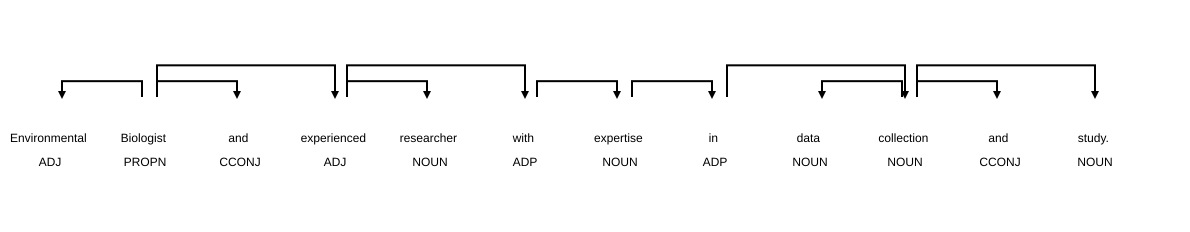

In [13]:
from src import parsing
parsing.main()
display(SVG("results/plots/dependency_parse_example.svg"))

## Practical 6 — N-grams, TF-IDF, Word2Vec, GloVe, contextual (BERT-family) embeddings

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 13338.03it/s]


[transformers] RobertaModel LOAD REPORT from: /home/claude/resume-analyzer-nlp/models/pretrained/roberta-base-spacy
Key                 | Status  | 
--------------------+---------+-
pooler.dense.bias   | MISSING | 
pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{
 "ngrams": {
  "1-gram": {
   "vocabulary_size": 1816,
   "top": [
    [
     "management",
     179
    ],
    [
     "report",
     151
    ],
    [
     "experience",
     142
    ],
    [
     "prepare",
     131
    ],
    [
     "work",
     130
    ],
    [
     "control",
     124
    ],
    [
     "present",
     122
    ],
    [
     "test",
     122
    ],
    [
     "maintain",
     119
    ],
    [
     "system",
     118
    ],
    [
     "use",
     116
    ],
    [
     "year",
     116
    ]
   ]
  },
  "2-gram": {
   "vocabulary_size": 2771,
   "top": [
    [
     "seed production",
     27
    ],
    [
     "ich gcp",
     27
    ],
    [
     "work experience",
     26
    ],
    [
     "core competency",
     25
    ],
    [
     "education training",
     24
    ],
    [
     "financial model",
     23
    ],
    [
     "employment history",
     23
    ],
    [
     "soil health",
     23
    ],
    [
     "attention detail",
     23
    ],
    [
     "professi

,representation,dimensions,n_samples,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,"Bag of n-grams (1-2, counts)",18716,100,0.98,0.9810,0.98,0.9800,0.9800
1,TF-IDF (1-2 grams),18715,100,0.95,0.9557,0.95,0.9501,0.9501
2,"Word2Vec (trained on corpus, mean)",100,100,0.98,0.9810,0.98,0.9800,0.9800
3,"GloVe 50-d (pretrained, mean)",50,100,0.98,0.9805,0.98,0.9800,0.9800
4,Contextual roberta-base-spacy (mean-pooled),768,100,0.93,0.9311,0.93,0.9299,0.9299


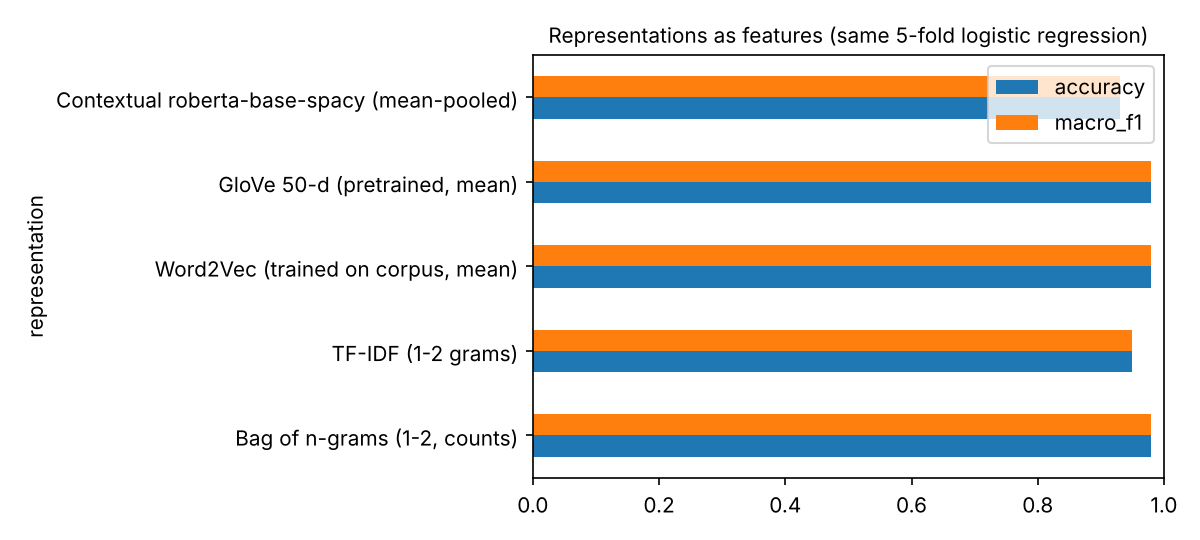

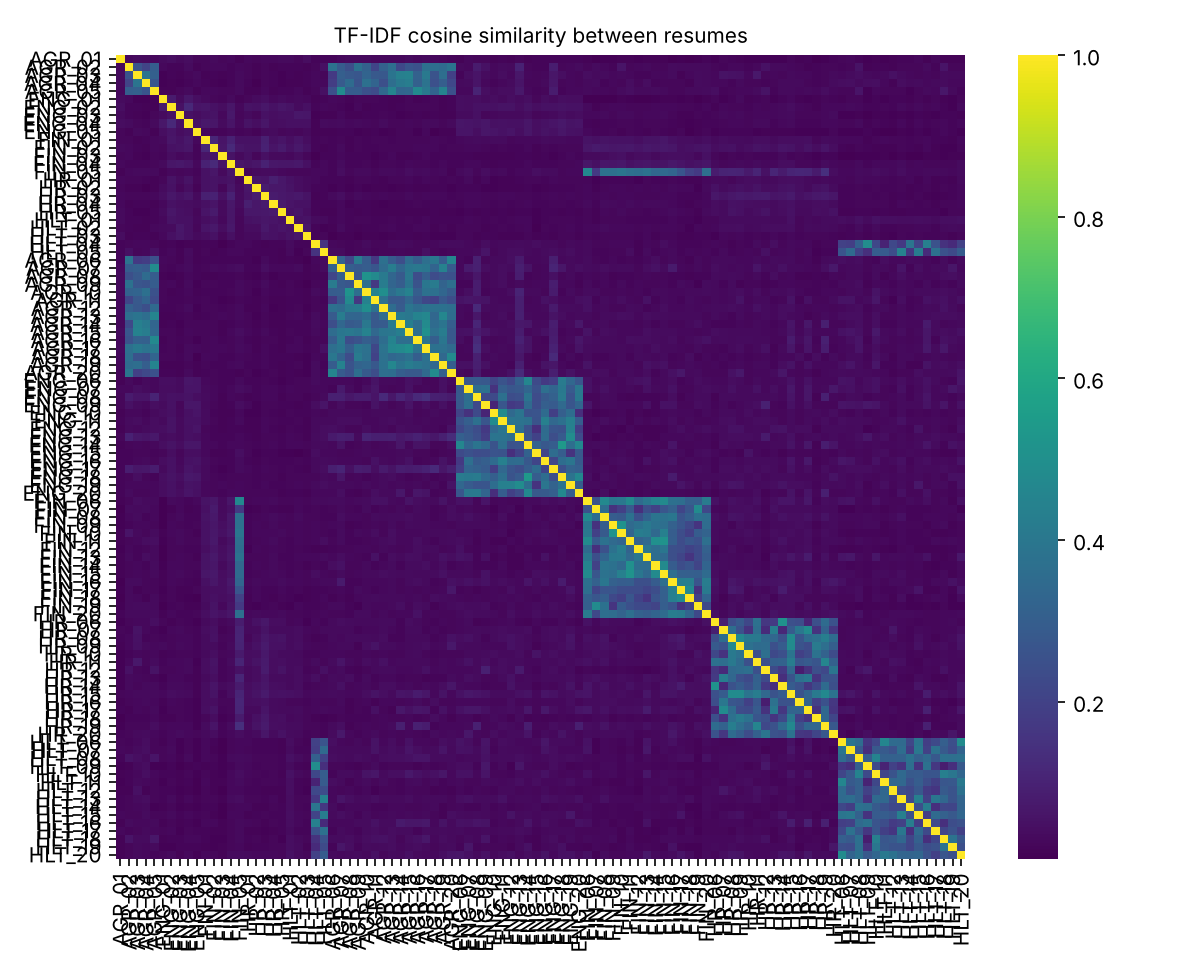

In [14]:
from src import text_representation
text_representation.main()
display(pd.read_csv("results/representation_comparison.csv"))
display(Image("results/plots/representation_comparison.png")); display(Image("results/plots/tfidf_similarity_heatmap.png"))

## Practical 7 — Morphological analysis

In [15]:
from src import morphology
morphology.main()


=== [HR_02] excellent time-management skills, team player, open and honest communicator, effective at maintaining confidentiality and multi-tasker.
           word           lemma   pos tag                       morph_features porter_stem prefix derivational_suffix inflectional_suffix        segmentation
      excellent       excellent   ADJ  JJ                           Degree=Pos       excel                                                          excellent
           time            time  NOUN  NN                          Number=Sing        time                                                               time
     management      management  NOUN  NN                          Number=Sing       manag                       ment                          manage + -ment
         skills           skill  NOUN NNS                          Number=Plur       skill                                              s          skill + -s
           team            team  NOUN  NN                    


=== [FIN_03] A versatile, highly motivated, adaptable, and responsible accounting graduate.
       word       lemma   pos tag            morph_features porter_stem prefix derivational_suffix inflectional_suffix    segmentation
          A           a   DET  DT Definite=Ind|PronType=Art           a                                                              a
  versatile   versatile   ADJ  JJ                Degree=Pos    versatil                                                      versatile
     highly      highly   ADV  RB                         -      highli                         ly                          high + -ly
  motivated   motivated   ADJ  JJ                Degree=Pos       motiv                                                      motivated
  adaptable   adaptable   ADJ  JJ                Degree=Pos       adapt                       able                       adapt + -able
        and         and CCONJ  CC              ConjType=Cmp         and                          


Corpus statistics: {
 "top_morph_features": [
  [
   "Number=Sing",
   17664
  ],
  [
   "Number=Plur",
   4608
  ],
  [
   "VerbForm=Part",
   2682
  ],
  [
   "Degree=Pos",
   2581
  ],
  [
   "Tense=Past",
   2562
  ],
  [
   "ConjType=Cmp",
   2421
  ],
  [
   "Aspect=Perf",
   1838
  ],
  [
   "Tense=Pres",
   1117
  ],
  [
   "VerbForm=Fin",
   1008
  ],
  [
   "PronType=Art",
   929
  ],
  [
   "Aspect=Prog",
   843
  ],
  [
   "VerbForm=Inf",
   579
  ],
  [
   "Definite=Def",
   557
  ],
  [
   "Definite=Ind",
   372
  ],
  [
   "Person=3",
   198
  ]
 ],
 "verb_tags": [
  [
   "VBN",
   1837
  ],
  [
   "VBG",
   843
  ],
  [
   "VBD",
   712
  ],
  [
   "VB",
   573
  ],
  [
   "VBZ",
   131
  ],
  [
   "VBP",
   97
  ]
 ],
 "derivational_suffixes": [
  [
   "-ment",
   989
  ],
  [
   "-al",
   958
  ],
  [
   "-ation",
   952
  ],
  [
   "-er",
   945
  ],
  [
   "-or",
   394
  ],
  [
   "-ity",
   326
  ],
  [
   "-ical",
   310
  ],
  [
   "-ance",
   287
  ],
  [
   "

## Practical 8 — HMM POS tagging (own Viterbi implementation vs NLTK HMM)


[HR_03] Human Resources Manager with practical understanding of business needs.
 HMM : Human/ADJ Resources/NOUN Manager/NOUN with/ADP practical/ADJ understanding/NOUN of/ADP business/NOUN needs/NOUN ./.
 Perc: Human/NOUN Resources/NOUN Manager/NOUN with/ADP practical/ADJ understanding/NOUN of/ADP business/NOUN needs/NOUN ./.
 agreement=0.90

[ENG_05] CAD CAM Finite Element Analysis Mechanical Design Product Design and Development
 HMM : CAD/NOUN CAM/NOUN Finite/NOUN Element/NOUN Analysis/NOUN Mechanical/ADJ Design/NOUN Product/NOUN Design/NOUN and/CONJ Development/NOUN
 Perc: CAD/NOUN CAM/NOUN Finite/NOUN Element/NOUN Analysis/NOUN Mechanical/NOUN Design/NOUN Product/NOUN Design/NOUN and/CONJ Development/NOUN
 agreement=0.91

[FIN_02] Financial Lead with company oversight, committed to strategic management and quality performance.
 HMM : Financial/ADJ Lead/NOUN with/ADP company/NOUN oversight/NOUN ,/. committed/VERB to/PRT strategic/ADJ management/NOUN and/CONJ quality/NOUN performanc


Held-out treebank accuracy: {'own_hmm_viterbi': 0.9453, 'nltk_hmm': 0.9067, 'most_frequent_tag_baseline': 0.9285}


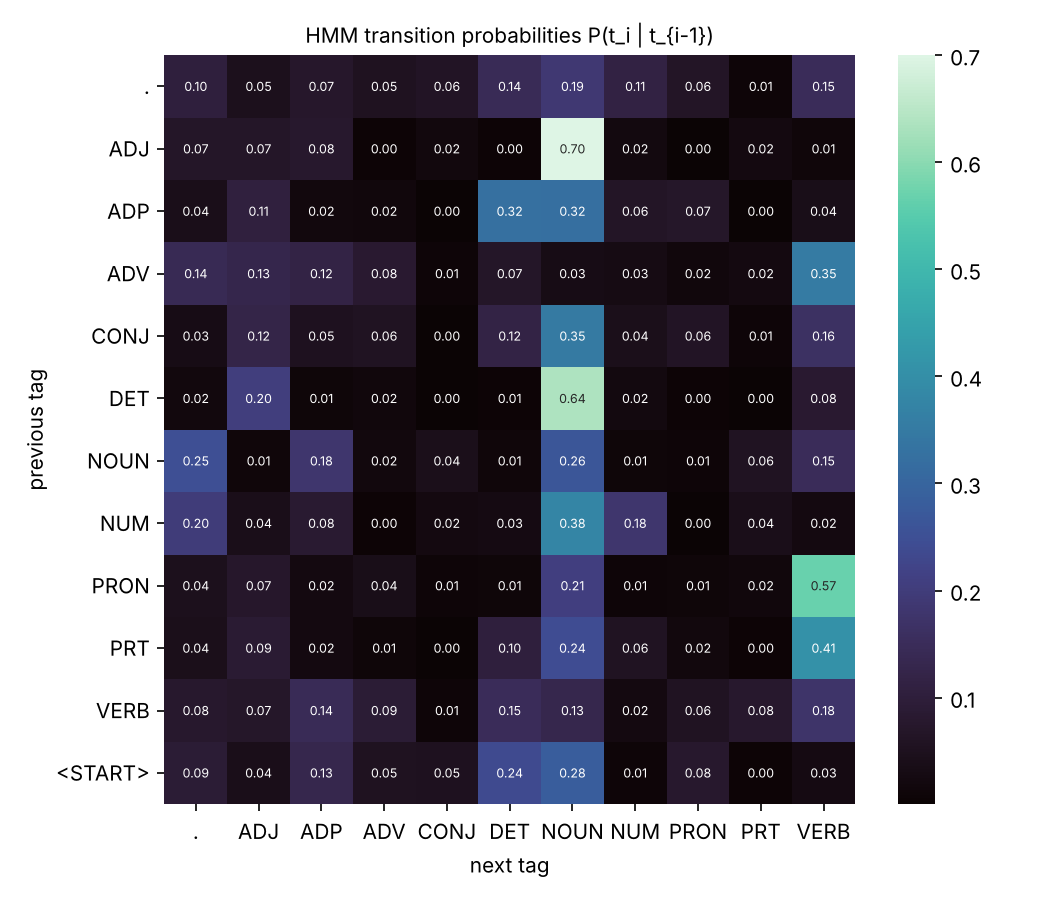

In [16]:
from src import hmm_pos_tagging
hmm_pos_tagging.main()
display(Image("results/plots/hmm_transition_matrix.png"))

## Practical 9 — Named Entity Recognition (pretrained spaCy + rule-based EntityRuler)

In [17]:
from src import ner
ner.main()

                  pretrained (en_core_web_sm)  rule-based (EntityRuler)  rule-based (regex)  pretrained (en_core_web_trf)
GPE                                       278                         0                   0                            11
PERSON                                    290                         0                   0                             4
ORG                                      2051                         0                   0                            53
WORK_OF_ART                                22                         0                   0                             1
DATE                                      719                         0                   0                            32
FAC                                        10                         0                   0                             0
NORP                                       52                         0                   0                             0
CARDINAL                

## Practical 10 — Baseline and transformer fine-tuning
* **Dataset:** 100 resumes (20 per category; 18 supplied originals + 82 clearly-labelled synthetic resumes), validated by `python -m src.validate_dataset`.
* **Split:** one resume-level split for both models — 60 train / 20 validation / 20 test (`data/processed/splits.csv`).
* **Baseline:** TF-IDF (1-2 grams) + Logistic Regression, trained on the 60 training resumes.
* **Transformer:** pretrained RoBERTa-base + new 5-class head, fine-tuned with an explicit PyTorch loop in `src/train_transformer.py` (forward pass → `CrossEntropyLoss` → `loss.backward()` → `optimizer.step()`), best epoch chosen on the validation resumes, test resumes used once.

`RUN_TRAINING=True` retrains (a few minutes on a Colab GPU; roughly half an hour on a 2-core CPU). With `False` the saved logs of the submitted run are shown.

In [18]:
import subprocess
print(subprocess.run(["python", "-m", "src.validate_dataset"], capture_output=True, text=True).stdout)
from src import train_baseline
train_baseline.main()

DATASET VALIDATION: PASS
  total resumes: 100
  Engineering   20  (original 5, synthetic 15)
  HR            20  (original 5, synthetic 15)
  Finance       20  (original 4, synthetic 16)
  Healthcare    20  (original 3, synthetic 17)
  Agriculture   20  (original 1, synthetic 19)
  words per resume: {'min': 225, 'max': 2070, 'mean': 426.6}
  max pairwise similarity: 0.777 (near-duplicate threshold 0.85)
  details: results/dataset_validation.json, results/dataset_validation_files.csv



{
 "train": {
  "n_samples": 60,
  "accuracy": 1.0,
  "macro_precision": 1.0,
  "macro_recall": 1.0,
  "macro_f1": 1.0,
  "weighted_f1": 1.0
 },
 "val": {
  "n_samples": 20,
  "accuracy": 0.95,
  "macro_precision": 0.96,
  "macro_recall": 0.95,
  "macro_f1": 0.9492,
  "weighted_f1": 0.9492
 },
 "test": {
  "n_samples": 20,
  "accuracy": 0.9,
  "macro_precision": 0.92,
  "macro_recall": 0.9,
  "macro_f1": 0.8984,
  "weighted_f1": 0.8984
 },
 "cv_5fold_all_100": {
  "n_samples": 100,
  "accuracy": 0.96,
  "macro_precision": 0.9636,
  "macro_recall": 0.96,
  "macro_f1": 0.9596,
  "weighted_f1": 0.9596
 }
}
saved /home/claude/resume-analyzer-nlp/models/baseline_tfidf_logreg.joblib


 epoch  train_loss  val_loss  val_accuracy  val_macro_f1  learning_rate_end  seconds  saved_as_best
     1     1.68593   1.61054          0.35        0.2300           0.000046    208.1           True
     2     1.64425   1.44982          0.40        0.2333           0.000037    198.2           True
     3     1.03309   0.17883          1.00        1.0000           0.000028    208.0           True
     4     0.09696   0.01502          1.00        1.0000           0.000019    196.4           True
     5     0.01491   0.00627          1.00        1.0000           0.000009    193.8           True
     6     0.00897   0.00537          1.00        1.0000           0.000000    179.9           True
{
 "model_used": "/home/claude/resume-analyzer-nlp/models/pretrained/roberta-base-spacy",
 "parameters": {
  "total_parameters": 124649477,
  "trainable_parameters": 124649477,
  "frozen_parameters": 0,
  "trainable_percent": 100.0,
  "frozen_embeddings": false,
  "frozen_encoder_layers": 0
 },
 "we

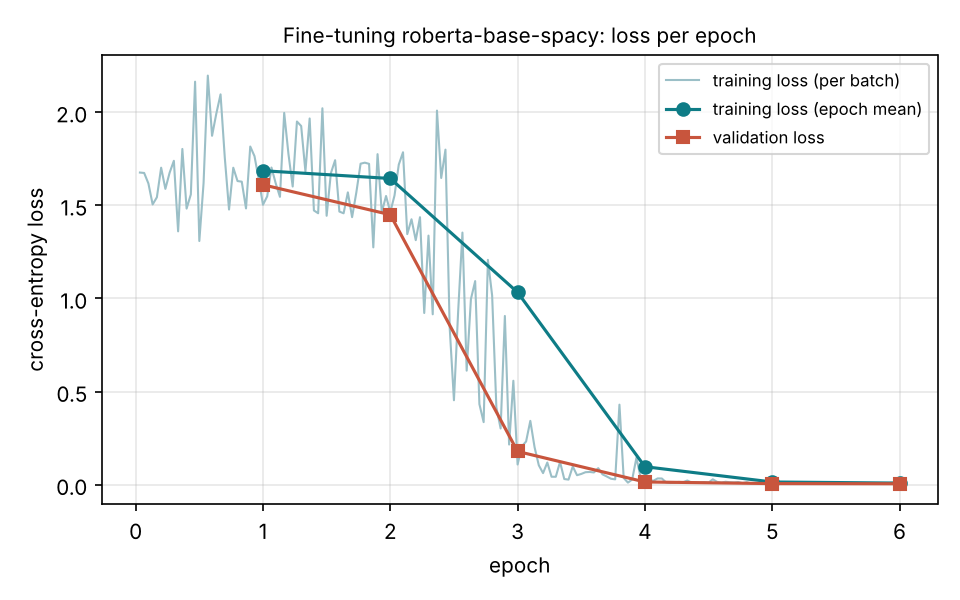

In [19]:
RUN_TRAINING = False   # set True to fine-tune live
if RUN_TRAINING:
    # downloads roberta-base from the Hugging Face Hub (falls back to models/pretrained/roberta-base-spacy offline)
    subprocess.run(["python", "-m", "src.train_transformer"], check=True)
print(pd.read_csv("results/transformer_training_log.csv").to_string(index=False))
ver = json.loads(Path("results/transformer_verification.json").read_text())
print(json.dumps({k: ver[k] for k in ("model_used", "parameters", "weight_change_after_first_optimizer_step",
                                       "weight_change_after_training", "reload_check")}, indent=1))
display(Image("results/plots/transformer_loss_curve.png"))

,model,split,resumes,n_samples,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,TF-IDF + Logistic Regression,test,all,20,0.90,0.920,0.90,0.8984,0.8984
1,TF-IDF + Logistic Regression,test,supplied_original,5,0.60,0.400,0.60,0.4667,0.4667
2,TF-IDF + Logistic Regression,test,synthetic,15,1.00,1.000,1.00,1.0000,1.0000
3,TF-IDF + Logistic Regression,val,all,20,0.95,0.960,0.95,0.9492,0.9492
4,TF-IDF + Logistic Regression,val,supplied_original,4,0.75,0.625,0.75,0.6667,0.6667
5,TF-IDF + Logistic Regression,val,synthetic,16,1.00,1.000,1.00,1.0000,1.0000
6,Fine-tuned transformer,test,all,20,1.00,1.000,1.00,1.0000,1.0000
7,Fine-tuned transformer,test,supplied_original,5,1.00,1.000,1.00,1.0000,1.0000
8,Fine-tuned transformer,test,synthetic,15,1.00,1.000,1.00,1.0000,1.0000
9,Fine-tuned transformer,val,all,20,1.00,1.000,1.00,1.0000,1.0000


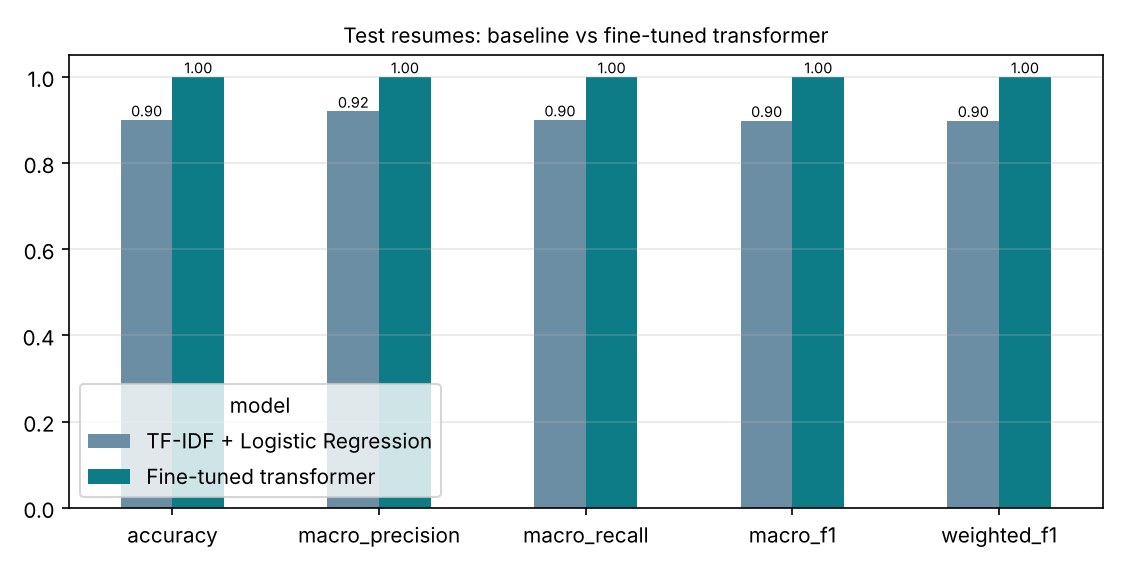

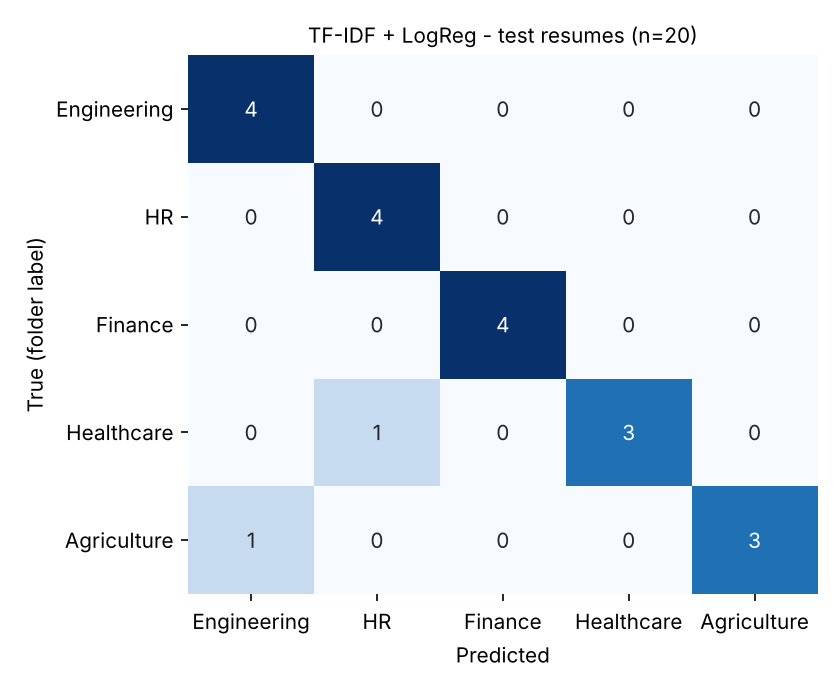

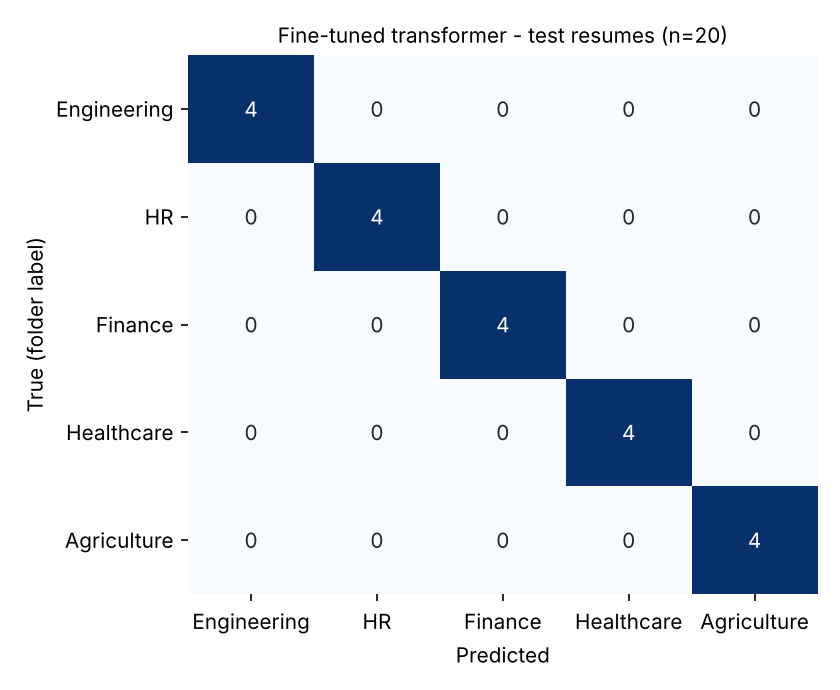

In [20]:
from src.evaluate import build_comparison
comp = build_comparison(); display(comp)
for p in ["results/plots/model_comparison.png", "results/plots/confusion_baseline_test.png",
          "results/plots/confusion_transformer_test.png"]:
    if Path(p).exists(): display(Image(p))

In [21]:
# sample predictions on the test resumes: true label vs predicted label (both models)
b = pd.read_csv("results/predictions_baseline.csv").query("split == 'test'")[["resume_id", "source_type", "true", "predicted"]]
t = pd.read_csv("results/predictions_transformer.csv").query("split == 'test'")[["resume_id", "predicted", "confidence"]]
display(b.merge(t, on="resume_id", suffixes=("_baseline", "_transformer")))

,resume_id,source_type,true,predicted_baseline,predicted_transformer,confidence
0,AGR_01,supplied_original,Agriculture,Engineering,Agriculture,0.9873
1,ENG_02,supplied_original,Engineering,Engineering,Engineering,0.9960
2,FIN_01,supplied_original,Finance,Finance,Finance,0.9937
3,HR_01,supplied_original,HR,HR,HR,0.9943
4,HLT_01,supplied_original,Healthcare,HR,Healthcare,0.9930
5,AGR_10,synthetic,Agriculture,Agriculture,Agriculture,0.9960
6,AGR_14,synthetic,Agriculture,Agriculture,Agriculture,0.9959
7,AGR_16,synthetic,Agriculture,Agriculture,Agriculture,0.9959
8,ENG_06,synthetic,Engineering,Engineering,Engineering,0.9961
9,ENG_15,synthetic,Engineering,Engineering,Engineering,0.9961


## Application demo (same code as the Streamlit app: `streamlit run app.py`)

In [22]:
from src.predict import analyze_file
res = analyze_file("data/raw/Engineering/10985403.pdf")
print("Skills:", [s["skill"] for s in res["skills"]][:15]); print("Titles:", res["job_titles"])
print("Classification:", json.dumps(res["classification"], indent=1)[:1200])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5775.50it/s]

Skills: ['manufacturing', 'cad', 'cam', 'finite element analysis', 'autocad', 'welding', 'solidworks', 'autodesk inventor', 'catia', 'ansys', 'bill of materials', 'prototyping', 'aerospace', 'mechanical design', 'product design']
Titles: ['Mechanical Engineering Intern', 'Manufacturing Engineering Intern']
Classification: {
 "warning": "PROTOTYPE CLASSIFIER: trained on 60 resumes (12 per class) from a 100-resume dataset in which 82 resumes are synthetic. Scores measured on 20 test resumes do not prove accuracy on real-world resumes; use the predictions as a demonstration of the pipeline, not as a decision tool.",
 "transformer": {
  "model": "fine-tuned transformer (transformer_finetuned, base: roberta-base-spacy, best epoch 6)",
  "predicted": "Engineering",
  "probabilities": {
   "Engineering": 0.9961,
   "Healthcare": 0.0012,
   "Finance": 0.0011,
   "Agriculture": 0.0009,
   "HR": 0.0008
  }
 },
 "baseline": {
  "model": "TF-IDF + Logistic Regression",
  "predicted": "Engineering"